# What Drives Resale-Condo Prices in Tokyo?
## Module 24 — Notebook 1 of 3: Data Cleaning, EDA and Inferential Statistics

**Author:** Sumit Mishra

### Problem
For someone looking to buy a resale condominium in Tokyo, it can be difficult to judge whether a listed price is reasonable. Property prices can vary significantly depending on factors such as location, building age, size and other property characteristics. Understanding what influences these prices can help buyers make more informed decisions and avoid overpaying.

### Research Question
Which property features have the greatest influence on resale condominium prices in Tokyo, and how accurately can these prices be estimated using machine learning?

### Data
This project uses publicly available real estate transaction data from the **MLIT Real Estate Information Library** in Japan. The dataset covers used condominiums in Tokyo from Q1 2015 to Q1 2026, containing **182,555 records and 21 columns**.

### Type of Problem
This is a **supervised machine learning regression problem**. The target variable is the property transaction price, and the objective is to predict its value based on the available property features.

### Change Since Module 16
The Module 16 proposal used the PaySim synthetic payments dataset to forecast payment failures. PaySim has no failure or status label and only ~30 days of simulated history, so it cannot answer that question. The project was therefore re-scoped to a real, public dataset with a well-defined target.


### What This Notebook Covers

1. Loading the dataset and translating Japanese column names and values into English.
2. Preparing the data by removing non-market transactions, non-residential properties and duplicate records, and addressing missing values.
3. Identifying and removing outliers using the IQR method applied separately to each municipality.
4. Creating additional features to support the analysis and model development.
5. Exploring property prices and their relationship with different characteristics through exploratory data analysis (EDA).
6. Using inferential statistical methods to further examine some of the patterns observed during the analysis.
7. Exporting the cleaned dataset for use in the next stage of modelling (Notebook 2).



In [1]:

import re
import unicodedata
import warnings

import numpy as np
import pandas as pd


import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.express as px
from IPython.display import Image, display

from scipy import stats
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore", category=FutureWarning)


sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)


DATA_PATH = "../data/raw/Tokyo_20151_20261.zip"
IMAGE_DIR = "../images"
RANDOM_STATE = 42

## 1. Load the Data
The MLIT dataset is provided as a CSV file inside a ZIP archive and uses Japanese encoding (Shift-JIS / cp932). Fortunately, pandas supports this encoding, so the data can be imported directly without manually extracting or converting the file first.

In [2]:
raw_df = pd.read_csv(DATA_PATH, encoding="cp932", compression="zip", low_memory=False)
print(f"Rows: {raw_df.shape[0]:,} | Columns: {raw_df.shape[1]}")
raw_df.head(3)

Rows: 182,555 | Columns: 21


,種類,価格情報区分,市区町村コード,都道府県名,市区町村名,地区名,最寄駅：名称,最寄駅：距離（分）,取引価格（総額）,間取り,面積（㎡）,建築年,建物の構造,用途,今後の利用目的,都市計画,建ぺい率（％）,容積率（％）,取引時期,改装,取引の事情等
0,中古マンション等,不動産取引価格情報,13101,東京都,千代田区,飯田橋,飯田橋,3,90000000,１ＬＤＫ,45,2012年,ＲＣ,住宅,住宅,商業,80.00,500.00,2026年第1四半期,未改装,NaN
1,中古マンション等,不動産取引価格情報,13101,東京都,千代田区,飯田橋,飯田橋,5,24000000,１Ｋ,20,2003年,ＲＣ,NaN,住宅,商業,80.00,500.00,2025年第4四半期,改装済み,NaN
2,中古マンション等,不動産取引価格情報,13101,東京都,千代田区,飯田橋,飯田橋,2,7600000,１Ｋ,15,1982年,ＳＲＣ,住宅,NaN,商業,80.00,700.00,2025年第4四半期,改装済み,NaN


### 1.1 Translate columns to English
The dataset originally contains Japanese column names, so I have renamed them using short, descriptive English names in snake_case format to make the data easier to understand and work with. Columns that require additional processing later in the notebook retain a _raw suffix to distinguish them from the cleaned versions.

In [3]:
COLUMN_MAP = {
    "種類": "property_type",
    "価格情報区分": "price_info_category",
    "市区町村コード": "municipality_code",
    "都道府県名": "prefecture",
    "市区町村名": "municipality_jp",
    "地区名": "district_jp",
    "最寄駅：名称": "nearest_station_jp",
    "最寄駅：距離（分）": "walk_raw",
    "取引価格（総額）": "price_yen",
    "間取り": "layout_raw",
    "面積（㎡）": "area_raw",
    "建築年": "build_year_raw",
    "建物の構造": "structure_raw",
    "用途": "current_use_raw",
    "今後の利用目的": "future_use_raw",
    "都市計画": "zoning_raw",
    "建ぺい率（％）": "coverage_ratio_pct",
    "容積率（％）": "floor_area_ratio_pct",
    "取引時期": "trade_period_raw",
    "改装": "renovation_raw",
    "取引の事情等": "special_circumstances_raw",
}
df = raw_df.rename(columns=COLUMN_MAP)

# A column with only one value carries no information
constant_cols = [col for col in df.columns if df[col].nunique(dropna=False) == 1]
print("Constant columns dropped:", constant_cols)
df = df.drop(columns=constant_cols)

Constant columns dropped: ['property_type', 'price_info_category', 'prefecture']


### 1.2 Data types and missing values

In [4]:
missing_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "unique_values": df.nunique(),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
}).sort_values("missing_pct", ascending=False)
missing_summary

,dtype,unique_values,missing_count,missing_pct
special_circumstances_raw,str,5,181273,99.30
current_use_raw,str,17,32361,17.73
renovation_raw,str,2,26777,14.67
layout_raw,str,47,9402,5.15
future_use_raw,str,4,8176,4.48
build_year_raw,str,74,4415,2.42
structure_raw,str,9,2965,1.62
floor_area_ratio_pct,float64,17,2320,1.27
coverage_ratio_pct,float64,5,2320,1.27
zoning_raw,str,16,1823,1.00


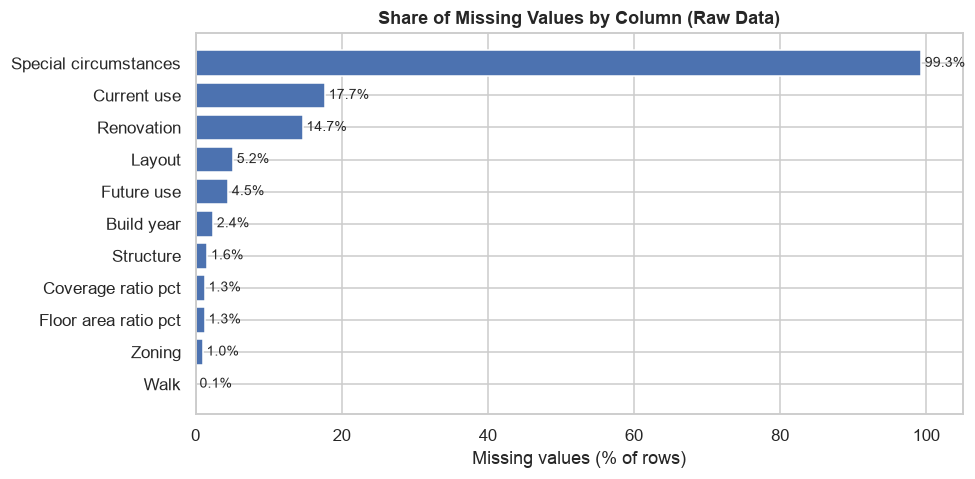

In [5]:
missing_plot = missing_summary.query("missing_pct > 0").sort_values("missing_pct")
labels = missing_plot.index.str.replace("_raw", "").str.replace("_", " ").str.capitalize()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(labels, missing_plot["missing_pct"], color="#4C72B0")
for y, pct in enumerate(missing_plot["missing_pct"]):
    ax.text(pct + 0.5, y, f"{pct:.1f}%", va="center", fontsize=9)
ax.set_title("Share of Missing Values by Column (Raw Data)")
ax.set_xlabel("Missing values (% of rows)")
ax.set_xlim(0, 105)
fig.savefig(f"{IMAGE_DIR}/01_missing_values.png", bbox_inches="tight", dpi=130)
plt.show()

### Observations

The special_circumstances_raw column is empty in 99.3% of the records. This is expected, as it is mainly used to identify and filter out transactions that do not represent normal market sales, rather than being used as a model feature.

Some categorical columns also have missing values, including renovation_raw (14.7%), current_use_raw (17.7%) and layout_raw (5.2%). Since these fields contain descriptive categories, I have kept the missing values as an explicit Unknown category instead of making assumptions about the missing information.

The numerical columns, such as build_year_raw, coverage_ratio_pct, floor_area_ratio_pct and walk_raw, have relatively few missing values (less than 2.5%). These will be handled through imputation or row removal, depending on the column and its relevance to the analysis.

## 2. Data Cleaning

### 2.1 Remove non-market transactions

The MLIT dataset identifies certain transactions as special cases, such as sales through court mediation or auctions, transactions between related parties (for example, family members), properties with potential defects, or sales involving other unusual conditions.

Since these transactions may not reflect normal market prices, I have excluded them from the analysis. Keeping them in the dataset could affect the model's ability to learn actual market pricing patterns and lead to less reliable predictions.

In [6]:
SPECIAL_MAP = {
    "調停・競売等": "Mediation / auction",
    "関係者間取引": "Related-party sale",
    "その他事情有り": "Other special circumstances",
    "瑕疵有りの可能性": "Possible defect",
    "他の権利・負担付き": "Encumbered by other rights",
}
print(df["special_circumstances_raw"].map(SPECIAL_MAP).value_counts().to_string())

rows_before = len(df)
df = df[df["special_circumstances_raw"].isna()].drop(columns="special_circumstances_raw")
print(f"\nRemoved {rows_before - len(df):,} non-market sales -> {len(df):,} rows remain")

special_circumstances_raw
Mediation / auction            1104
Related-party sale              156
Other special circumstances      13
Possible defect                   8
Encumbered by other rights        1

Removed 1,282 non-market sales -> 181,273 rows remain


### 2.2 Keep residential units

Some condominium units are used for purposes other than residential living, such as offices, shops, warehouses or parking spaces. Since these properties may follow different pricing patterns from residential condominiums, including them could affect the accuracy of the analysis.

To keep the dataset focused on the residential market, I have removed units whose recorded use is exclusively non-residential. Records with missing or unknown usage information have been retained, as most condominium units in Tokyo are residential properties.

In [7]:
is_residential_or_unknown = (
    df["current_use_raw"].isna() | df["current_use_raw"].str.contains("住宅", na=False)
)
rows_before = len(df)
df = df[is_residential_or_unknown].copy()
print(f"Removed {rows_before - len(df):,} non-residential units -> {len(df):,} rows remain")

# Keep a simple flag; drop the buyer's *future* use (intent, not a property feature)
df["use_recorded"] = np.where(df["current_use_raw"].isna(), "Unknown", "Residential")
df = df.drop(columns=["current_use_raw", "future_use_raw"])

Removed 1,507 non-residential units -> 179,766 rows remain


### 2.3 Duplicate records

MLIT anonymises and rounds certain published values, such as transaction prices, floor areas and construction years. As a result, two different condominium units in the same building, sold during the same quarter at the same price, may appear identical in the dataset. This makes it difficult to determine whether identical records are genuine duplicates or separate transactions.

Since exact duplicates account for only a small portion of the dataset, I have removed them for two main reasons: to avoid giving identical records additional weight during model training and to reduce the risk of the same records appearing in both the training and test datasets, which could lead to data leakage.

In [8]:
duplicate_count = df.duplicated().sum()
print(f"Exact duplicate rows: {duplicate_count:,} ({duplicate_count / len(df):.2%})")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows after removing duplicates: {len(df):,}")

Exact duplicate rows: 1,523 (0.85%)
Rows after removing duplicates: 178,243


### 2.4 Parse text fields into numbers

A quick comparison of the original raw values and their corresponding parsed values for the selected fields.

### Raw Data Fields and Parsing Rules

| Raw field | Example raw values | Parsed feature | Parsing rule |
|:---|:---|:---|:---|
| `trade_period_raw` | `2025年第4四半期` | `trade_year`, `trade_quarter`, `time_index` | Extract the year and quarter. `time_index` counts quarters starting from 2015 Q1. |
| `walk_raw` | `5`, `30分～60分`, `1H～1H30`, `2H～` | `walk_min` | For time ranges, use the midpoint. Values such as 2 hours or more are capped at 120 minutes. |
| `area_raw` | `45`, `2,000㎡以上` | `area_sqm` | Convert the area into a numeric value. Values recorded as 2,000 m² or more are set to 2,000. |
| `build_year_raw` | `2005年`, `戦前` | `build_year` | Extract the construction year. The term `戦前` (pre-war) is assigned 1945. |
| `layout_raw` | `３ＬＤＫ＋Ｓ`, `１Ｋ`, `オープンフロア` | `rooms`, `has_living_dining`, `has_storage_room`, `layout_type` | Normalise full-width characters, then extract the room count and relevant layout indicators. |

In [9]:
# Transaction period: "2025年第4四半期" -> year 2025, quarter 4
period = df["trade_period_raw"].str.extract(r"(\d{4})年第(\d)四半期").astype(int)
df["trade_year"] = period[0]
df["trade_quarter"] = period[1]
df["time_index"] = (df["trade_year"] - 2015) * 4 + (df["trade_quarter"] - 1)   # 0 = 2015 Q1
df["trade_period"] = df["trade_year"].astype(str) + " Q" + df["trade_quarter"].astype(str)

# Walking time: ranges become their midpoint, "2 hours or more" is capped at 120
WALK_RANGE_MAP = {"30分～60分": 45, "1H～1H30": 75, "1H30～2H": 105, "2H～": 120}
df["walk_min"] = pd.to_numeric(df["walk_raw"].replace(WALK_RANGE_MAP), errors="coerce")

# Floor area: the top-coded value "2,000㎡以上" ("2,000 m² or more") becomes 2000
df["area_sqm"] = pd.to_numeric(df["area_raw"].replace({"2,000㎡以上": "2000"}), errors="coerce")

# Year built: "2005年" -> 2005; "戦前" ("pre-war") -> 1945
df["build_year"] = pd.to_numeric(
    df["build_year_raw"].replace({"戦前": "1945年"}).str.replace("年", "", regex=False),
    errors="coerce",
)

df[["walk_min", "area_sqm", "build_year", "trade_year"]].describe().T[["count", "mean", "min", "50%", "max"]]

,count,mean,min,50%,max
walk_min,"178,150.00",7.61,0.00,6.00,120.00
area_sqm,"178,243.00",46.61,10.00,50.00,"2,000.00"
build_year,"173,902.00","2,000.07","1,945.00","2,003.00","2,025.00"
trade_year,"178,243.00","2,020.19","2,015.00","2,020.00","2,026.00"


### 2.5 Parse layouts

In [10]:
def parse_layout(layout):
    """Turn a layout code such as '3LDK+S' into numeric features."""
    if pd.isna(layout):
        return pd.Series({"rooms": np.nan, "has_living_dining": np.nan,
                          "has_storage_room": np.nan, "layout_type": "Unknown"})
    code = unicodedata.normalize("NFKC", layout)          # full-width -> normal characters
    special = {"オープンフロア": "Open floor", "スタジオ": "Studio", "メゾネット": "Maisonette"}
    if code in special:
        rooms = 1 if code == "スタジオ" else np.nan      # a studio is one room
        return pd.Series({"rooms": rooms, "has_living_dining": 0,
                          "has_storage_room": 0, "layout_type": special[code]})
    match = re.match(r"(\d+)", code)
    base = code.split("+")[0]
    return pd.Series({
        "rooms": int(match.group(1)) if match else np.nan,
        "has_living_dining": int("L" in base and "D" in base),
        "has_storage_room": int("+S" in code),
        "layout_type": base,
    })


# Parse each distinct layout once (47 values), then join back onto all rows
layout_lookup = pd.DataFrame({"layout_raw": df["layout_raw"].unique()})
layout_lookup = layout_lookup.join(layout_lookup["layout_raw"].apply(parse_layout))
df = df.merge(layout_lookup, on="layout_raw", how="left")

df[["layout_raw", "rooms", "has_living_dining", "has_storage_room", "layout_type"]].drop_duplicates().head(8)

,layout_raw,rooms,has_living_dining,has_storage_room,layout_type
0,１ＬＤＫ,1.00,1.00,0.00,1LDK
1,１Ｋ,1.00,0.00,0.00,1K
3,３ＬＤＫ,3.00,1.00,0.00,3LDK
5,２ＬＤＫ,2.00,1.00,0.00,2LDK
7,１ＬＤＫ＋Ｓ,1.00,1.00,1.00,1LDK
8,２ＤＫ,2.00,0.00,0.00,2DK
9,１Ｒ,1.00,0.00,0.00,1R
10,１ＤＫ,1.00,0.00,0.00,1DK


### 2.6 Translate categories to English

Municipality, building structure, zoning and renovation status have been converted into English labels for easier interpretation. The original Japanese district and station names are retained for Module 24 (location encoding), but excluded from the visualisations.

In [11]:
MUNICIPALITY_EN = {
    13101: "Chiyoda", 13102: "Chuo", 13103: "Minato", 13104: "Shinjuku", 13105: "Bunkyo",
    13106: "Taito", 13107: "Sumida", 13108: "Koto", 13109: "Shinagawa", 13110: "Meguro",
    13111: "Ota", 13112: "Setagaya", 13113: "Shibuya", 13114: "Nakano", 13115: "Suginami",
    13116: "Toshima", 13117: "Kita", 13118: "Arakawa", 13119: "Itabashi", 13120: "Nerima",
    13121: "Adachi", 13122: "Katsushika", 13123: "Edogawa",
    13201: "Hachioji", 13202: "Tachikawa", 13203: "Musashino", 13204: "Mitaka", 13205: "Ome",
    13206: "Fuchu", 13207: "Akishima", 13208: "Chofu", 13209: "Machida", 13210: "Koganei",
    13211: "Kodaira", 13212: "Hino", 13213: "Higashimurayama", 13214: "Kokubunji",
    13215: "Kunitachi", 13218: "Fussa", 13219: "Komae", 13220: "Higashiyamato",
    13221: "Kiyose", 13222: "Higashikurume", 13223: "Musashimurayama", 13224: "Tama",
    13225: "Inagi", 13227: "Hamura", 13228: "Akiruno", 13229: "Nishitokyo", 13303: "Mizuho",
}
STRUCTURE_EN = {"ＲＣ": "RC (reinforced concrete)", "ＳＲＣ": "SRC (steel-reinforced concrete)",
                "鉄骨造": "Steel frame"}
ZONING_EN = {
    "商業": "Commercial", "近隣商業": "Neighbourhood commercial", "準工業": "Quasi-industrial",
    "工業": "Industrial", "１中住専": "Mid/high-rise residential", "２中住専": "Mid/high-rise residential",
    "１低住専": "Low-rise residential", "２低住専": "Low-rise residential",
    "１種住居": "Residential", "２種住居": "Residential", "準住居": "Quasi-residential",
}
RENOVATION_EN = {"改装済み": "Renovated", "未改装": "Not renovated"}

df["municipality"] = df["municipality_code"].map(MUNICIPALITY_EN)
df["area_group"] = np.where(df["municipality_code"] < 13200, "23 Wards", "Tama Area")
df["structure"] = df["structure_raw"].map(STRUCTURE_EN).fillna("Mixed / other")
df.loc[df["structure_raw"].isna(), "structure"] = "Unknown"
df["zoning"] = df["zoning_raw"].map(ZONING_EN).fillna("Other / unknown")
df["renovation"] = df["renovation_raw"].map(RENOVATION_EN).fillna("Unknown")

assert df["municipality"].notna().all(), "Unmapped municipality code found"
df[["municipality", "area_group", "structure", "zoning", "renovation"]].value_counts().head(5)

municipality  area_group  structure                        zoning                     renovation   
Koto          23 Wards    RC (reinforced concrete)         Quasi-industrial           Not renovated    3142
Taito         23 Wards    RC (reinforced concrete)         Commercial                 Not renovated    2334
Chuo          23 Wards    RC (reinforced concrete)         Commercial                 Not renovated    2182
Setagaya      23 Wards    RC (reinforced concrete)         Mid/high-rise residential  Not renovated    1885
Chuo          23 Wards    SRC (steel-reinforced concrete)  Commercial                 Not renovated    1748
Name: count, dtype: int64

### 2.7 Handle remaining missing values

Median is preferred over mean because property prices and related features often contain extreme values that can skew the average. It provides a more reliable representation of typical values and helps avoid distortion when filling missing data.

### Missing Value Handling Strategy

| Column | Missing values | Imputation strategy | Reason |
|:---|---:|:---|:---|
| `walk_min` | ~0.05% | Remove rows with missing values | Very few records are affected, and station distance is an important pricing factor. Guessing these values could introduce unnecessary noise. |
| `build_year` | ~2.4% | Use the median construction year from the same district, then the municipality if needed. | Buildings within the same neighbourhood are more likely to have similar construction periods. |
| `coverage_ratio_pct`, `floor_area_ratio_pct` | ~1.3% | Use the median value from the same district, then the municipality. | These zoning limits are generally determined by the local area. |
| `rooms` | ~5% | Use the median room count for properties with similar floor areas (10 m² bands). | The number of rooms is closely related to the overall floor area. |
| `has_living_dining`, `has_storage_room` | ~5% | Assign 0 and retain `layout_type = "Unknown"`. | This allows the model to recognise that the layout information was not available. |
| Categorical fields | — | Retain missing values under the `Unknown` category. | Missing information is preserved rather than replaced with an assumed category. |

In [12]:
rows_before = len(df)
df = df.dropna(subset=["walk_min", "area_sqm"]).copy()
print(f"Dropped {rows_before - len(df):,} rows with missing walking time or area")


def impute_by_group(frame, column, groups):
    """Fill gaps with the median of the first matching group, then the next one, then overall."""
    filled = frame[column].copy()
    for group in groups:
        filled = filled.fillna(frame.groupby(group)[column].transform("median"))
    return filled.fillna(frame[column].median())


for col in ["build_year", "coverage_ratio_pct", "floor_area_ratio_pct"]:
    df[col] = impute_by_group(df, col, groups=["district_jp", "municipality"])

# Rooms: median of flats with similar floor area (10 m² bands)
area_band = (df["area_sqm"] // 10).clip(upper=20)
df["rooms"] = df["rooms"].fillna(df.groupby(area_band)["rooms"].transform("median"))
df[["has_living_dining", "has_storage_room"]] = df[["has_living_dining", "has_storage_room"]].fillna(0)

model_cols = ["walk_min", "area_sqm", "build_year", "rooms", "coverage_ratio_pct",
              "floor_area_ratio_pct", "has_living_dining", "has_storage_room"]
print("Missing values left in model columns:", int(df[model_cols].isna().sum().sum()))

Dropped 93 rows with missing walking time or area
Missing values left in model columns: 0


## 3. Feature Engineering

### building_age
How it is calculated: Difference between the transaction year and construction year (minimum 0)

Why it is useful: Helps understand how the age of a building affects its resale value.


### price_per_sqm
How it is calculated: Property price divided by floor area

Why it is useful: Makes it easier to compare properties of different sizes and identify unusual prices.


### log_price
How it is calculated: logarithm of the property price

Why it is useful : Helps handle the skewed distribution of property prices and allows the model to capture percentage-based changes.


### walk_bucket 
How it is calculated : Groups walking time into different ranges

Why it is useful : Makes walking distance patterns easier to understand in charts.


### age_bucket
How it is calculated: Groups buildings into age ranges 

Why it is useful : Makes it easier to compare prices across buildings of different ages.


### layout_group  
How it is calculated: Keeps common layouts separate and combines less common ones 

Why it is useful : Reduces the number of categories and makes visualisations easier to interpret.



In [13]:
df["building_age"] = (df["trade_year"] - df["build_year"]).clip(lower=0)
df["price_per_sqm"] = df["price_yen"] / df["area_sqm"]
df["log_price"] = np.log(df["price_yen"])

df["walk_bucket"] = pd.cut(df["walk_min"], bins=[-1, 5, 10, 15, 20, 30, 200],
                           labels=["0-5", "6-10", "11-15", "16-20", "21-30", "30+"])
df["age_bucket"] = pd.cut(df["building_age"], bins=[-1, 5, 10, 20, 30, 40, 100],
                          labels=["0-5", "6-10", "11-20", "21-30", "31-40", "40+"])

COMMON_LAYOUTS = ["1R", "1K", "1DK", "1LDK", "2DK", "2LDK", "3LDK", "4LDK"]
df["layout_group"] = np.where(df["layout_type"].isin(COMMON_LAYOUTS), df["layout_type"],
                              np.where(df["layout_type"] == "Unknown", "Unknown", "Other"))

df[["price_yen", "area_sqm", "price_per_sqm", "building_age", "walk_min", "rooms"]].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
price_yen,"178,150.00","40,620,266.60","61,525,196.40","50,000.00","21,000,000.00","30,000,000.00","48,000,000.00","16,000,000,000.00"
area_sqm,"178,150.00",46.60,24.90,10.00,25.00,50.00,65.00,"2,000.00"
price_per_sqm,"178,150.00","891,800.40","558,170.70","3,333.30","573,333.30","857,142.90","1,120,000.00","100,000,000.00"
building_age,"178,150.00",20.10,13.00,0.00,10.00,17.00,28.00,80.00
walk_min,"178,150.00",7.60,5.90,0.00,4.00,6.00,10.00,120.00
rooms,"178,150.00",1.80,0.90,1.00,1.00,2.00,3.00,6.00


## 4. Outlier Analysis

The initial analysis reveals some unusually high and low transaction values. Some properties are recorded at just a few hundred thousand yen, while others reach billions of yen. There are also a small number of units with floor areas exceeding 300 m².

This raises two questions:

1. Are these incorrect records or unusual transactions, such as bulk purchases, partial ownership sales or commercial properties?
2. Or are they genuine but uncommon properties, such as luxury apartments and penthouses?

Method: Property prices per square metre can vary significantly across Tokyo, depending on the location. For example, properties in central areas like Minato can be several times more expensive than those in outer areas such as Tama. Applying one fixed threshold across all of Tokyo could incorrectly classify expensive central properties as outliers.

To avoid this, I have applied the IQR method to log-transformed price per square metre within each municipality. A transaction is flagged as an outlier if its value falls more than 1.5 × IQR below Q1 or above Q3 for its respective municipality. Using the log scale helps account for differences in price ratios rather than relying on absolute price differences.

In [14]:
log_ppsqm = np.log(df["price_per_sqm"])
q1 = log_ppsqm.groupby(df["municipality"]).transform("quantile", 0.25)
q3 = log_ppsqm.groupby(df["municipality"]).transform("quantile", 0.75)
iqr = q3 - q1
df["is_price_outlier"] = (log_ppsqm < q1 - 1.5 * iqr) | (log_ppsqm > q3 + 1.5 * iqr)


df["is_size_outlier"] = df["area_sqm"] > 300

outlier_summary = pd.DataFrame({
    "rows_flagged": [df["is_price_outlier"].sum(), df["is_size_outlier"].sum(),
                     (df["is_price_outlier"] | df["is_size_outlier"]).sum()],
}, index=["Price per m² outside municipality IQR fence", "Floor area > 300 m²", "Either rule"])
outlier_summary["pct_of_rows"] = (outlier_summary["rows_flagged"] / len(df) * 100).round(2)
outlier_summary

,rows_flagged,pct_of_rows
Price per m² outside municipality IQR fence,4398,2.47
Floor area > 300 m²,17,0.01
Either rule,4405,2.47


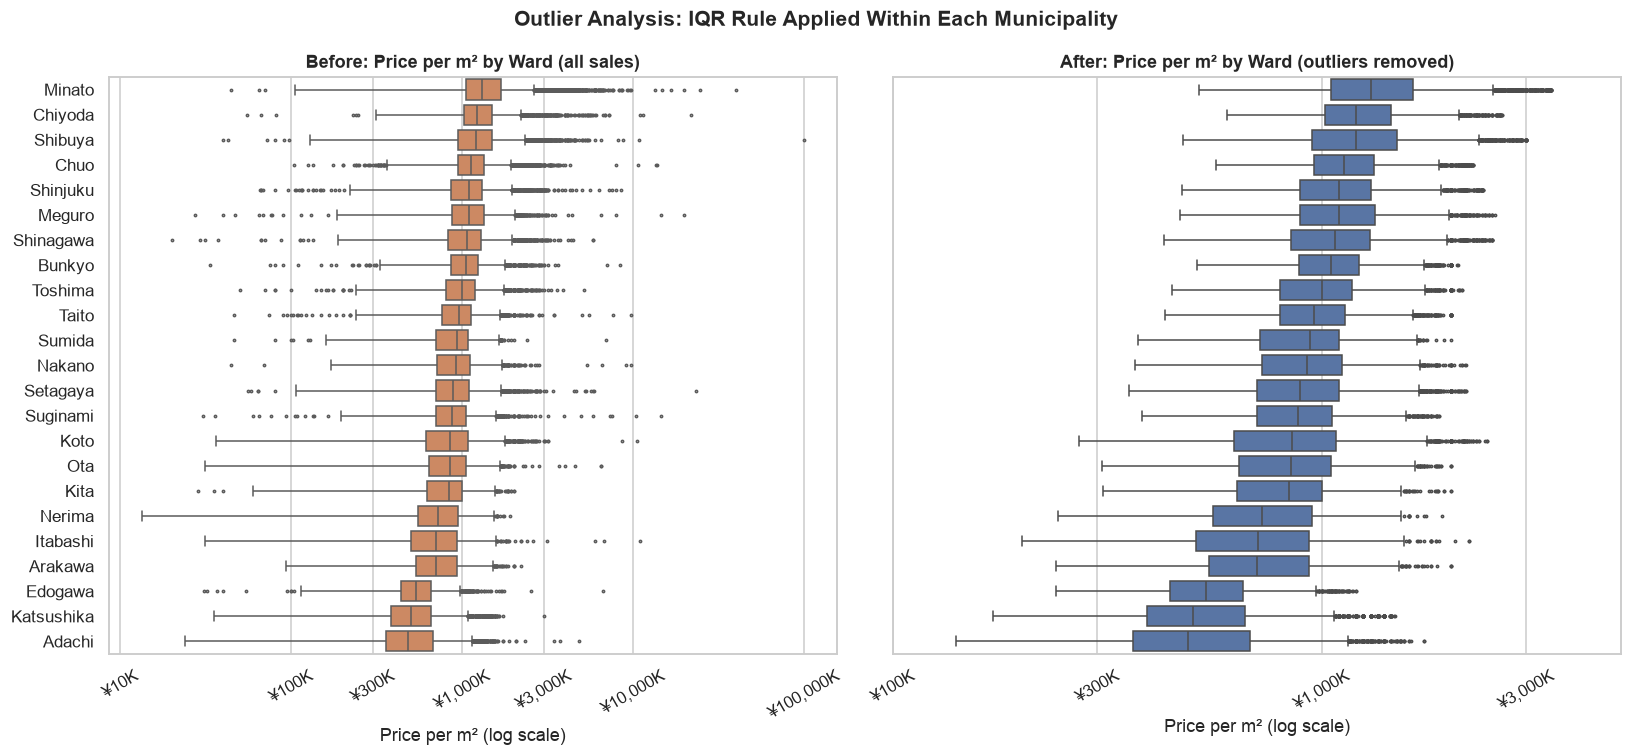

In [15]:
def yen_thousands(x, _pos=None):
    """Axis label formatter: 850000 -> '¥850K'."""
    return f"¥{x / 1e3:,.0f}K"


ward_df = df[df["area_group"] == "23 Wards"]
ward_order = ward_df.groupby("municipality")["price_per_sqm"].median().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
sns.boxplot(data=ward_df, y="municipality", x="price_per_sqm", order=ward_order,
            ax=axes[0], color="#DD8452", fliersize=1.5)
axes[0].set_title("Before: Price per m² by Ward (all sales)")

sns.boxplot(data=ward_df[~ward_df["is_price_outlier"]], y="municipality", x="price_per_sqm",
            order=ward_order, ax=axes[1], color="#4C72B0", fliersize=1.5)
axes[1].set_title("After: Price per m² by Ward (outliers removed)")

for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks([1e4, 1e5, 3e5, 1e6, 3e6, 1e7, 1e8])
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(yen_thousands))
    ax.xaxis.set_minor_formatter(mtick.NullFormatter())
    ax.tick_params(axis="x", rotation=30)
    ax.set_xlabel("Price per m² (log scale)")
    ax.set_ylabel("")
axes[1].set_xlim(1e5, 5e6)

fig.suptitle("Outlier Analysis: IQR Rule Applied Within Each Municipality", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{IMAGE_DIR}/02_outliers_before_after.png", bbox_inches="tight", dpi=130)
plt.show()

In [16]:
outlier_group = pd.Series(
    np.select([df["is_price_outlier"] & (log_ppsqm < q1), df["is_price_outlier"]],
              ["Low-price outlier", "High-price outlier"], default="Normal sale"),
    index=df.index, name="group")
profile_cols = ["price_yen", "price_per_sqm", "area_sqm", "building_age", "walk_min"]
outlier_profile = df.groupby(outlier_group)[profile_cols].median()
outlier_profile["count"] = outlier_group.value_counts()
outlier_profile

,price_yen,price_per_sqm,area_sqm,building_age,walk_min,count
group,,,,,,
High-price outlier,"210,000,000.00","3,047,619.05",70.00,10.00,4.00,1368
Low-price outlier,"9,000,000.00","275,000.00",40.00,38.00,7.00,3030
Normal sale,"31,000,000.00","866,666.67",50.00,17.00,6.00,173752


### Interpretation and Decision

\- Low-price outliers: Around 3,000 transactions fall into this category, with a median price of ¥9M and ¥275K/m². This is less than one-third of the typical sale price of ¥867K/m². The buildings also have a median age of 38 years. These transactions may involve partial ownership, properties with undisclosed issues or possible data entry errors.

\- High-price outliers: Around 1,400 transactions fall into this group, with a median price of ¥210M and ¥3.05M/m². These are likely to be luxury properties in newer buildings, with a median age of just 10 years, selling at prices well above the typical range for their municipality.

\- Removal decision: Together, these outliers account for approximately 2.5% of the dataset. Since the objective is to build a fair-price estimator for ordinary residential properties, I have removed both groups, along with the 17 units exceeding 300 m².

\- Limitation: The resulting model is not intended to estimate prices for ultra-luxury properties or distressed sales. This limitation is also documented in the project README.

\- Final check: After removing these records, the price distributions across Tokyo's wards became more consistent, while the overall ranking of the wards remained unchanged. This suggests that the removal reduced extreme values without significantly affecting the underlying market patterns.

In [17]:
rows_before = len(df)
clean_df = df[~(df["is_price_outlier"] | df["is_size_outlier"])].copy()
clean_df = clean_df.drop(columns=["is_price_outlier", "is_size_outlier"])
print(f"Removed {rows_before - len(clean_df):,} outlier rows -> {len(clean_df):,} rows in the clean dataset")
print(f"Kept {len(clean_df) / len(raw_df):.1%} of the original {len(raw_df):,} transactions")

Removed 4,405 outlier rows -> 173,745 rows in the clean dataset
Kept 95.2% of the original 182,555 transactions


## 5. Exploratory Data Analysis

In [18]:
def yen_millions(x, _pos=None):
    """Axis label formatter: 45000000 -> '¥45M'."""
    return f"¥{x / 1e6:,.0f}M"


def show_plotly(fig, name):
    """Save a Plotly chart as PNG and display it.
    GitHub can't render interactive Plotly output, so a static image is shown instead."""
    path = f"{IMAGE_DIR}/{name}.png"
    try:
        fig.write_image(path, width=1000, height=520, scale=2)
        display(Image(path, width=900))
    except Exception:
        fig.show()   

### 5.1 The target: transaction price

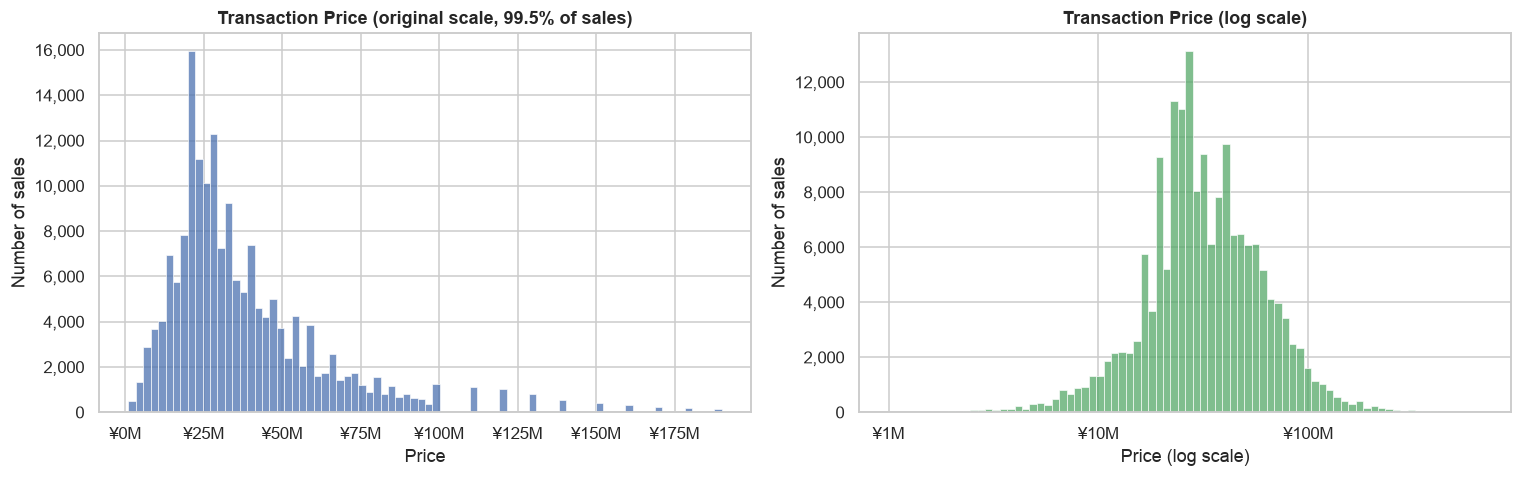

Skewness: original = 3.73, log = -0.11


In [19]:
price_cap = clean_df["price_yen"].quantile(0.995)     # zoom in on 99.5% of sales

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(clean_df.loc[clean_df["price_yen"] <= price_cap, "price_yen"], bins=80,
             ax=axes[0], color="#4C72B0")
axes[0].set_title("Transaction Price (original scale, 99.5% of sales)")
axes[0].set_xlabel("Price")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(yen_millions))

sns.histplot(clean_df["price_yen"], bins=80, log_scale=True, ax=axes[1], color="#55A868")
axes[1].set_title("Transaction Price (log scale)")
axes[1].set_xlabel("Price (log scale)")
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(yen_millions))

for ax in axes:
    ax.set_ylabel("Number of sales")
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
fig.tight_layout()
fig.savefig(f"{IMAGE_DIR}/03_price_distribution.png", bbox_inches="tight", dpi=130)
plt.show()

print(f"Skewness: original = {clean_df['price_yen'].skew():.2f}, log = {clean_df['log_price'].skew():.2f}")

Property prices are heavily right-skewed, with a skewness of 3.7. Most condominiums sell for between ¥21M and ¥48M, while a smaller number of expensive properties create a long tail in the distribution. After applying a log transformation, the distribution becomes much more balanced and closer to symmetric.

For this reason, the models in Notebook 2 uses `log_price` as its target variable. This also makes the prediction errors easier to interpret in percentage terms. For example, a ¥5M error is much more significant for a ¥20M property than for a ¥200M property, and the log transformation helps account for this difference.

### 5.2 Location

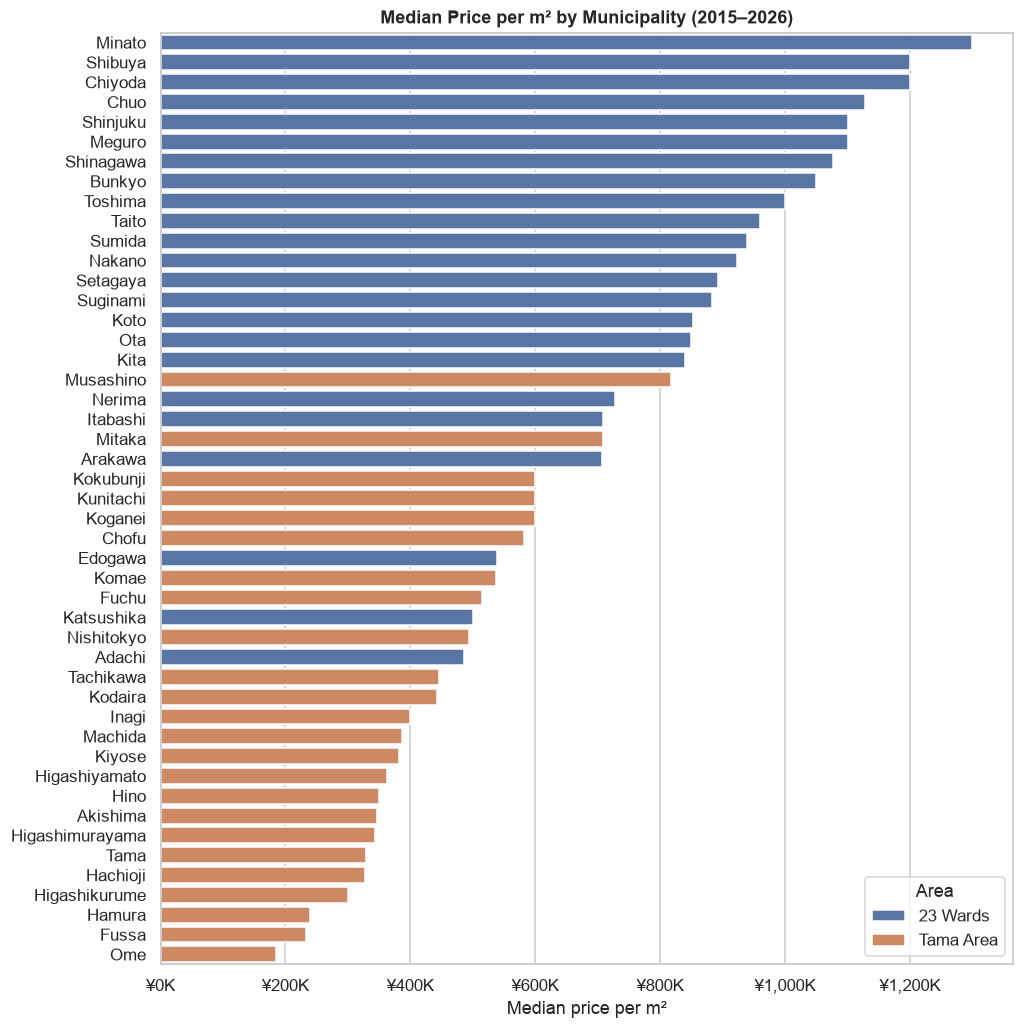

Most expensive: Minato (¥1,300,000/m²) | Least expensive: Ome (¥184,615/m²) | Ratio: 7.0x


In [20]:
muni_stats = (clean_df.groupby(["municipality", "area_group"])
              .agg(median_ppsqm=("price_per_sqm", "median"), sales=("price_yen", "size"))
              .reset_index()
              .query("sales >= 100")                    # skip towns with too few sales
              .sort_values("median_ppsqm", ascending=False))

fig, ax = plt.subplots(figsize=(10, 11))
sns.barplot(data=muni_stats, y="municipality", x="median_ppsqm", hue="area_group", dodge=False,
            palette={"23 Wards": "#4C72B0", "Tama Area": "#DD8452"}, ax=ax)
ax.set_title("Median Price per m² by Municipality (2015–2026)")
ax.set_xlabel("Median price per m²")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(yen_thousands))
ax.legend(title="Area", loc="lower right")
fig.savefig(f"{IMAGE_DIR}/04_price_by_municipality.png", bbox_inches="tight", dpi=130)
plt.show()

top, bottom = muni_stats.iloc[0], muni_stats.iloc[-1]
print(f"Most expensive: {top.municipality} (¥{top.median_ppsqm:,.0f}/m²) | "
      f"Least expensive: {bottom.municipality} (¥{bottom.median_ppsqm:,.0f}/m²) | "
      f"Ratio: {top.median_ppsqm / bottom.median_ppsqm:.1f}x")

Location appears to be the biggest factor influencing resale condominium prices. Properties in central wards such as Minato, Chiyoda, Chuo and Shibuya are several times more expensive per square metre than those in the outer Tama areas. In fact, almost all of Tokyo's 23 wards have higher property prices than the Tama cities. This makes location an important feature that the model must capture to produce reliable price predictions.

### 5.3 Time

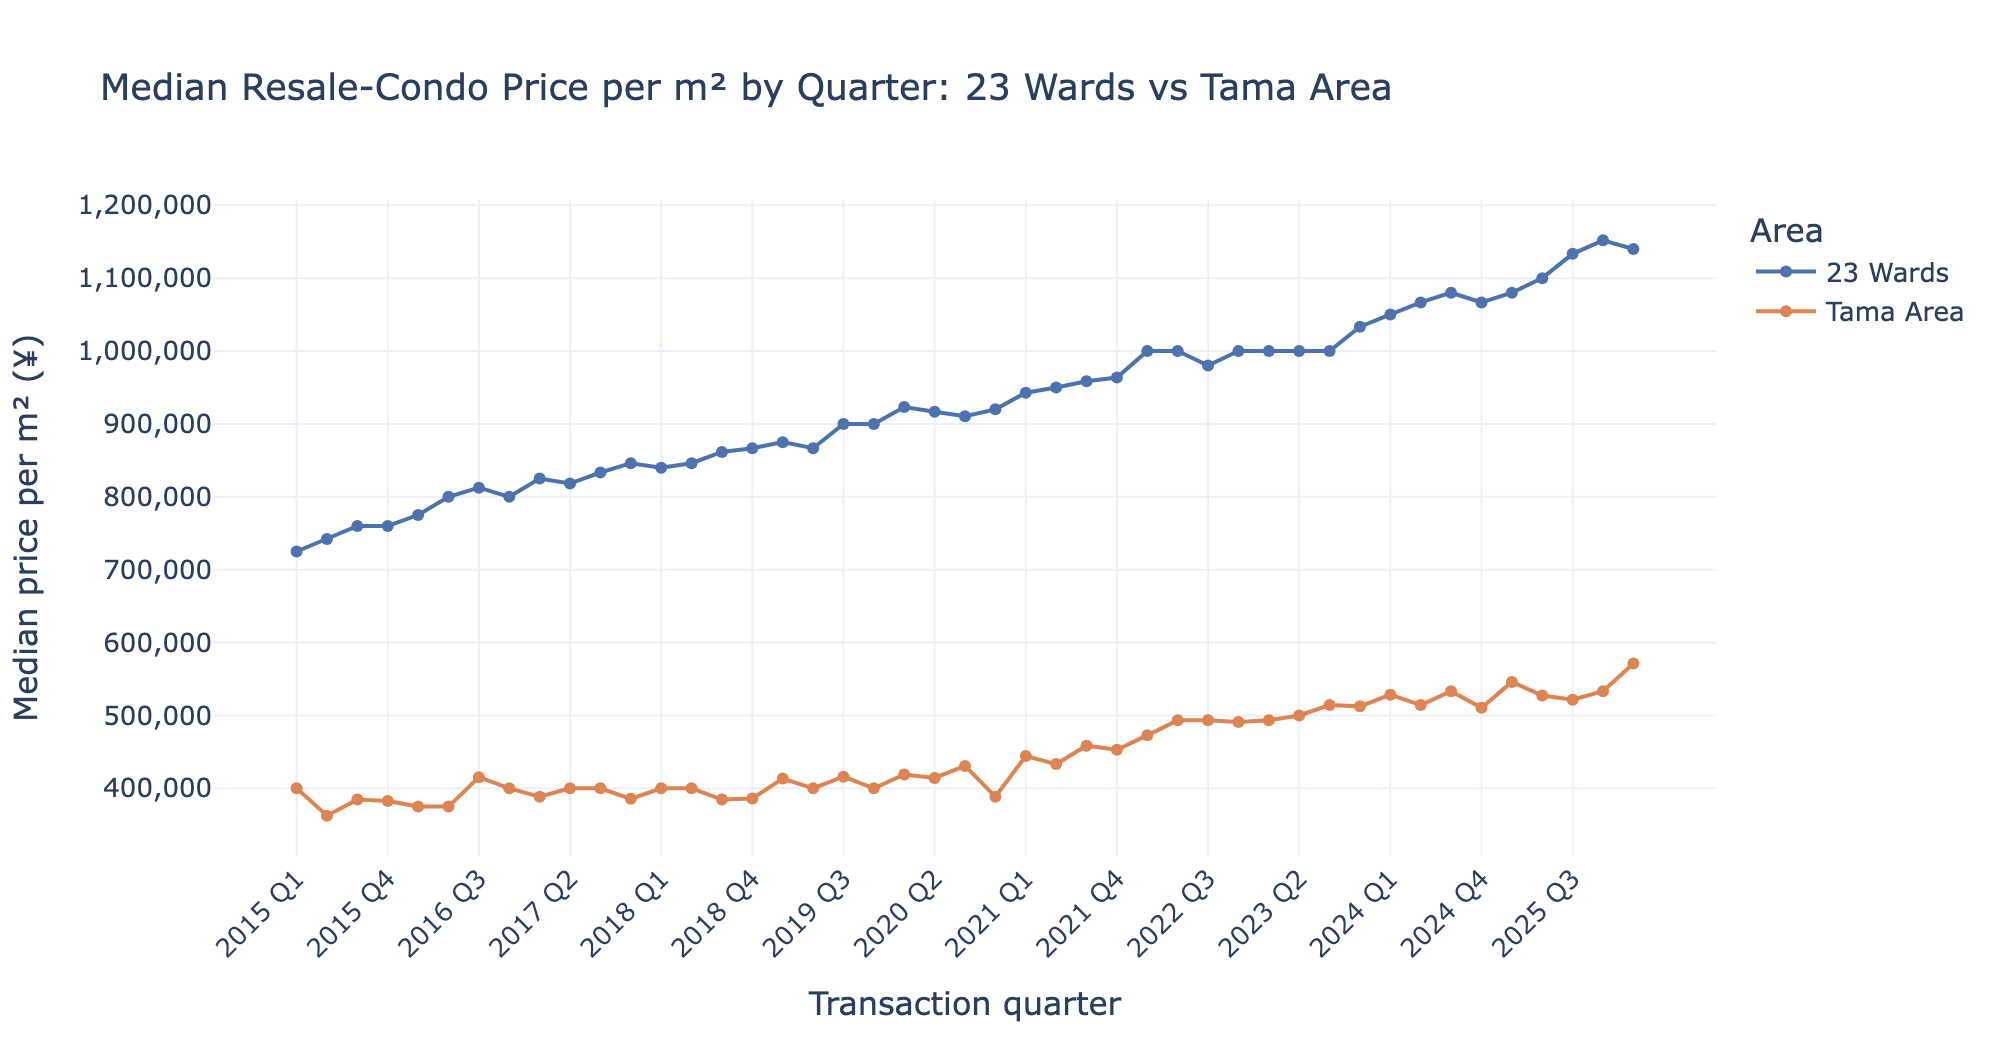

Change 2015 Q1 -> 2025 Q4:
area_group
23 Wards     58.9%
Tama Area    33.3%


In [21]:
trend_df = (clean_df.groupby(["time_index", "trade_period", "area_group"])["price_per_sqm"]
            .median().reset_index().sort_values("time_index"))

fig = px.line(trend_df, x="trade_period", y="price_per_sqm", color="area_group", markers=True,
              labels={"trade_period": "Transaction quarter",
                      "price_per_sqm": "Median price per m² (¥)", "area_group": "Area"},
              title="Median Resale-Condo Price per m² by Quarter: 23 Wards vs Tama Area",
              color_discrete_map={"23 Wards": "#4C72B0", "Tama Area": "#DD8452"})
fig.update_layout(template="plotly_white", xaxis_tickangle=-45, yaxis_tickformat=",.0f",
                  font=dict(size=13))
fig.update_xaxes(nticks=23)
show_plotly(fig, "05_price_trend")

first_q = trend_df[trend_df["time_index"] == 0].set_index("area_group")["price_per_sqm"]
last_q = trend_df[trend_df["trade_period"] == "2025 Q4"].set_index("area_group")["price_per_sqm"]
print("Change 2015 Q1 -> 2025 Q4:")
print(((last_q / first_q - 1) * 100).round(1).astype(str).add("%").to_string())

Property prices have increased steadily over the past decade, with a faster rise across Tokyo's 23 wards compared to the outer areas. This trend has two important implications for the model:

1. Transaction date matters: The `time_index` feature is important because property prices change over time, and the model needs to account for these market trends.
2. Time-based train/test split: A random split could allow the model to learn from newer transactions and then predict older ones, giving an unrealistic evaluation. Instead, tthe models in Notebook 2 is trained on historical transactions and tested on the most recent sales, which better reflects how it would perform in a real-world scenario.

### 5.4 Station distance and building age

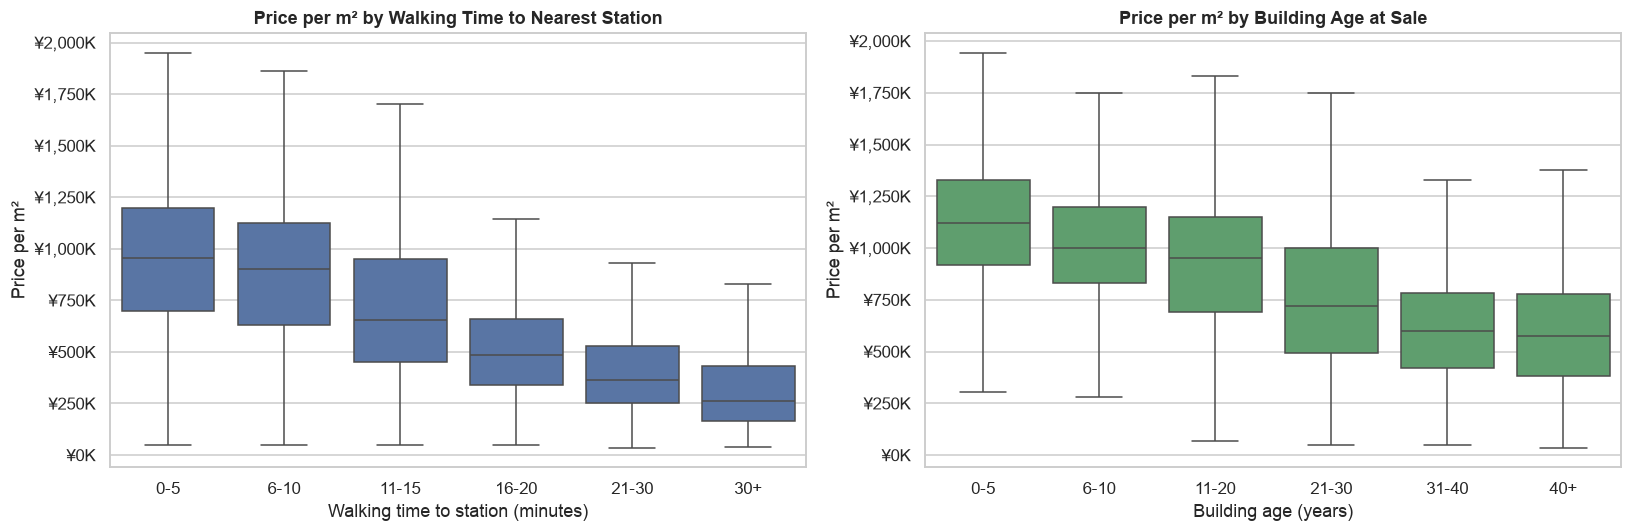

0-5 min vs 21-30 min walk: 2.64x price per m²
0-5 yr vs 31-40 yr old:    1.87x price per m²


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=clean_df, x="walk_bucket", y="price_per_sqm", ax=axes[0],
            color="#4C72B0", showfliers=False)
axes[0].set_title("Price per m² by Walking Time to Nearest Station")
axes[0].set_xlabel("Walking time to station (minutes)")

sns.boxplot(data=clean_df, x="age_bucket", y="price_per_sqm", ax=axes[1],
            color="#55A868", showfliers=False)
axes[1].set_title("Price per m² by Building Age at Sale")
axes[1].set_xlabel("Building age (years)")

for ax in axes:
    ax.set_ylabel("Price per m²")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(yen_thousands))
fig.tight_layout()
fig.savefig(f"{IMAGE_DIR}/06_walk_and_age.png", bbox_inches="tight", dpi=130)
plt.show()

walk_med = clean_df.groupby("walk_bucket", observed=True)["price_per_sqm"].median()
age_med = clean_df.groupby("age_bucket", observed=True)["price_per_sqm"].median()
print(f"0-5 min vs 21-30 min walk: {walk_med['0-5'] / walk_med['21-30']:.2f}x price per m²")
print(f"0-5 yr vs 31-40 yr old:    {age_med['0-5'] / age_med['31-40']:.2f}x price per m²")

\- Station distance: Property prices per square metre generally decrease as walking time to the nearest station increases. The drop is gradual up to around 10 minutes, but becomes more noticeable beyond that. Flats within a 5-minute walk of a station sell for approximately 2.6 times more per square metre than those located 21–30 minutes away. However, location also plays a role, as properties farther from stations are more common in the outer Tama areas. The models in Notebook 2 will help separate the impact of station distance from the impact of location.

\- Building age: Property prices per square metre decline steadily as buildings get older, particularly during the first 30–40 years. Newly built properties sell for approximately 1.9 times more per square metre than those aged 31–40 years. After that, the decline becomes less noticeable, suggesting that land value and location account for a larger share of the property's overall value than the building itself.

### 5.5 Size and layout

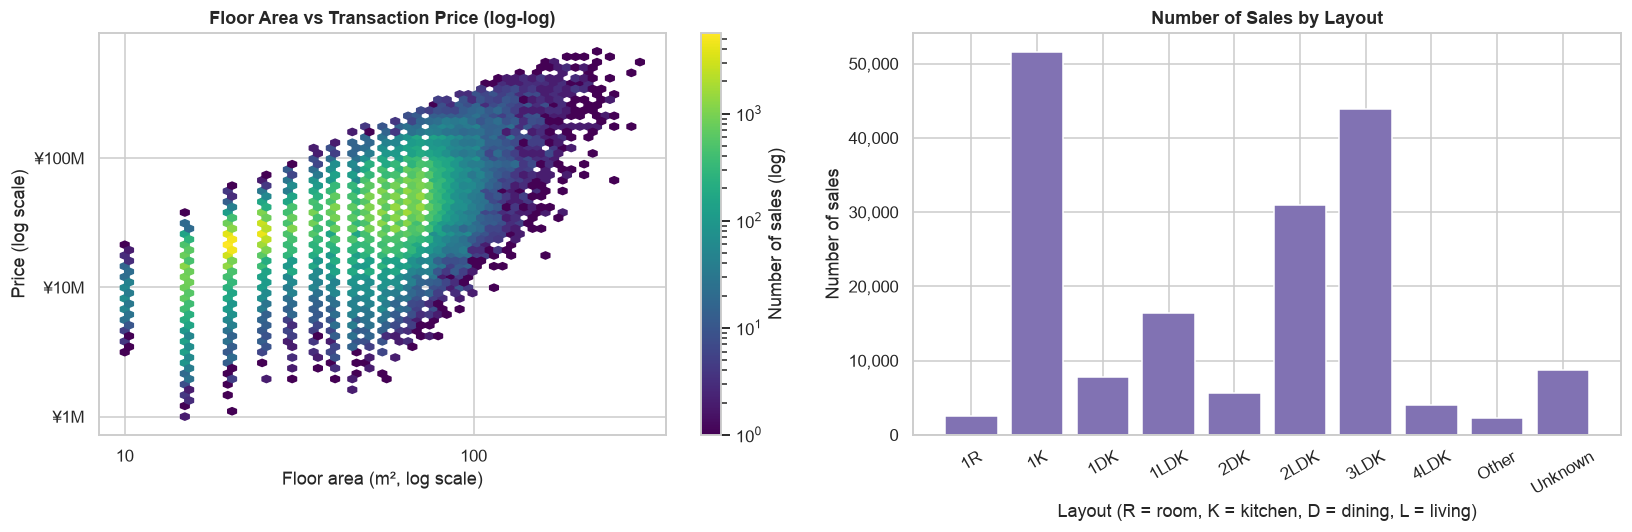

Correlation between log(area) and log(price): 0.65


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))


hb = axes[0].hexbin(clean_df["area_sqm"], clean_df["price_yen"], gridsize=60, bins="log",
                    cmap="viridis", xscale="log", yscale="log", mincnt=1)
axes[0].set_title("Floor Area vs Transaction Price (log-log)")
axes[0].set_xlabel("Floor area (m², log scale)")
axes[0].set_ylabel("Price (log scale)")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(yen_millions))
axes[0].xaxis.set_major_formatter(mtick.ScalarFormatter())
fig.colorbar(hb, ax=axes[0], label="Number of sales (log)")

layout_order = COMMON_LAYOUTS + ["Other", "Unknown"]
layout_counts = clean_df["layout_group"].value_counts().reindex(layout_order)
axes[1].bar(layout_counts.index, layout_counts.values, color="#8172B3")
axes[1].set_title("Number of Sales by Layout")
axes[1].set_xlabel("Layout (R = room, K = kitchen, D = dining, L = living)")
axes[1].set_ylabel("Number of sales")
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
axes[1].tick_params(axis="x", rotation=30)

fig.tight_layout()
fig.savefig(f"{IMAGE_DIR}/07_size_and_layout.png", bbox_inches="tight", dpi=130)
plt.show()

corr_area = np.corrcoef(np.log(clean_df["area_sqm"]), clean_df["log_price"])[0, 1]
print(f"Correlation between log(area) and log(price): {corr_area:.2f}")

\- Floor area: Larger flats generally sell for higher prices, showing a strong, roughly linear relationship on a log-log scale. However, the increase in price is not directly proportional to the increase in floor area.

\- Property layout: The market is largely split between two types of properties: 1K studio apartments, which are often purchased as investment properties, and 2LDK/3LDK apartments, which are more commonly suited to families. This difference in property types helps explain the wide variation in overall transaction prices.

### 5.6 Building structure and renovation status

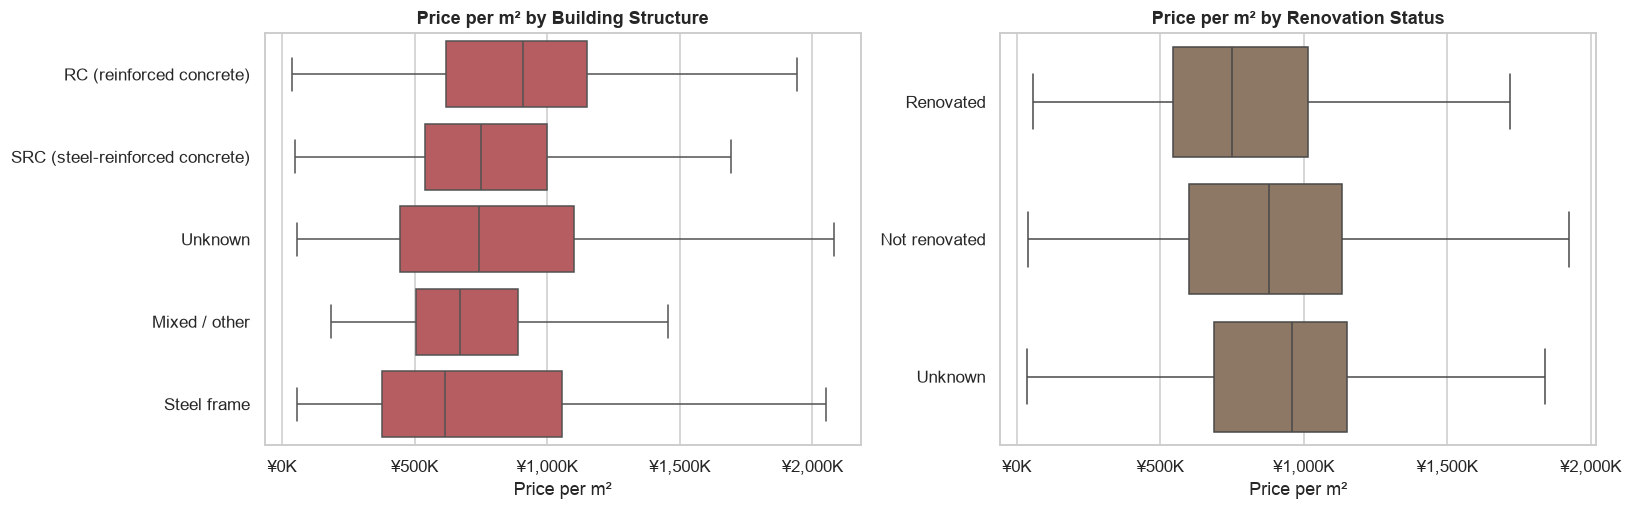

,price_per_sqm,building_age
renovation,,
Not renovated,"880,000.00",15.00
Renovated,"750,000.00",25.00
Unknown,"960,000.00",16.00


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

structure_order = (clean_df.groupby("structure")["price_per_sqm"].median()
                   .sort_values(ascending=False).index)
sns.boxplot(data=clean_df, y="structure", x="price_per_sqm", order=structure_order,
            ax=axes[0], color="#C44E52", showfliers=False)
axes[0].set_title("Price per m² by Building Structure")

sns.boxplot(data=clean_df, y="renovation", x="price_per_sqm",
            order=["Renovated", "Not renovated", "Unknown"], ax=axes[1],
            color="#937860", showfliers=False)
axes[1].set_title("Price per m² by Renovation Status")

for ax in axes:
    ax.set_xlabel("Price per m²")
    ax.set_ylabel("")
    ax.xaxis.set_major_locator(mtick.MultipleLocator(500_000))
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(yen_thousands))
fig.tight_layout()
fig.savefig(f"{IMAGE_DIR}/08_structure_and_renovation.png", bbox_inches="tight", dpi=130)
plt.show()


clean_df.groupby("renovation")[["price_per_sqm", "building_age"]].median().round(0)

In [25]:

structure_stats = (clean_df.groupby("structure")
                   .agg(share_of_sales_pct=("price_yen", "size"),
                        median_price_per_sqm=("price_per_sqm", "median"),
                        median_building_age=("building_age", "median"))
                   .sort_values("share_of_sales_pct", ascending=False))
structure_stats["share_of_sales_pct"] = (structure_stats["share_of_sales_pct"]
                                         / len(clean_df) * 100).round(1)
structure_stats.round({"share_of_sales_pct": 1, "median_price_per_sqm": 0, "median_building_age": 0})

,share_of_sales_pct,median_price_per_sqm,median_building_age
structure,,,
RC (reinforced concrete),72.30,"909,091.00",14.00
SRC (steel-reinforced concrete),25.30,"750,000.00",27.00
Unknown,1.60,"742,857.00",19.00
Steel frame,0.60,"613,333.00",31.00
Mixed / other,0.20,"671,429.00",26.00


From the structure table above:

\- Building structure: Most properties are either RC (reinforced concrete), accounting for 72% of the dataset, or SRC (steel-reinforced concrete), accounting for 25%. Interestingly, SRC properties have a lower median price per m² than RC properties (¥750K vs ¥909K). However, SRC buildings are generally older, with a median age of 27 years compared to 14 years for RC buildings. This suggests that the price difference is largely related to building age rather than the construction type itself.

\- Renovation status: Renovated properties also show a lower median price per m² than non-renovated ones (¥750K vs ¥880K). At first, this seems unexpected, but renovated properties tend to be older, with a median age of 25 years compared to 15 years for non-renovated properties. The age difference may be masking the actual price benefit of renovation.

\- Key takeaway – Confounding: Both examples show how looking at one feature in isolation can lead to misleading conclusions. Other factors, such as building age, can influence the relationship between a feature and property price. This is why a multivariable model is important: it allows us to compare renovated and non-renovated properties while accounting for differences in building age (tested in Section 6.2 below).

### 5.7 Where condos are sold

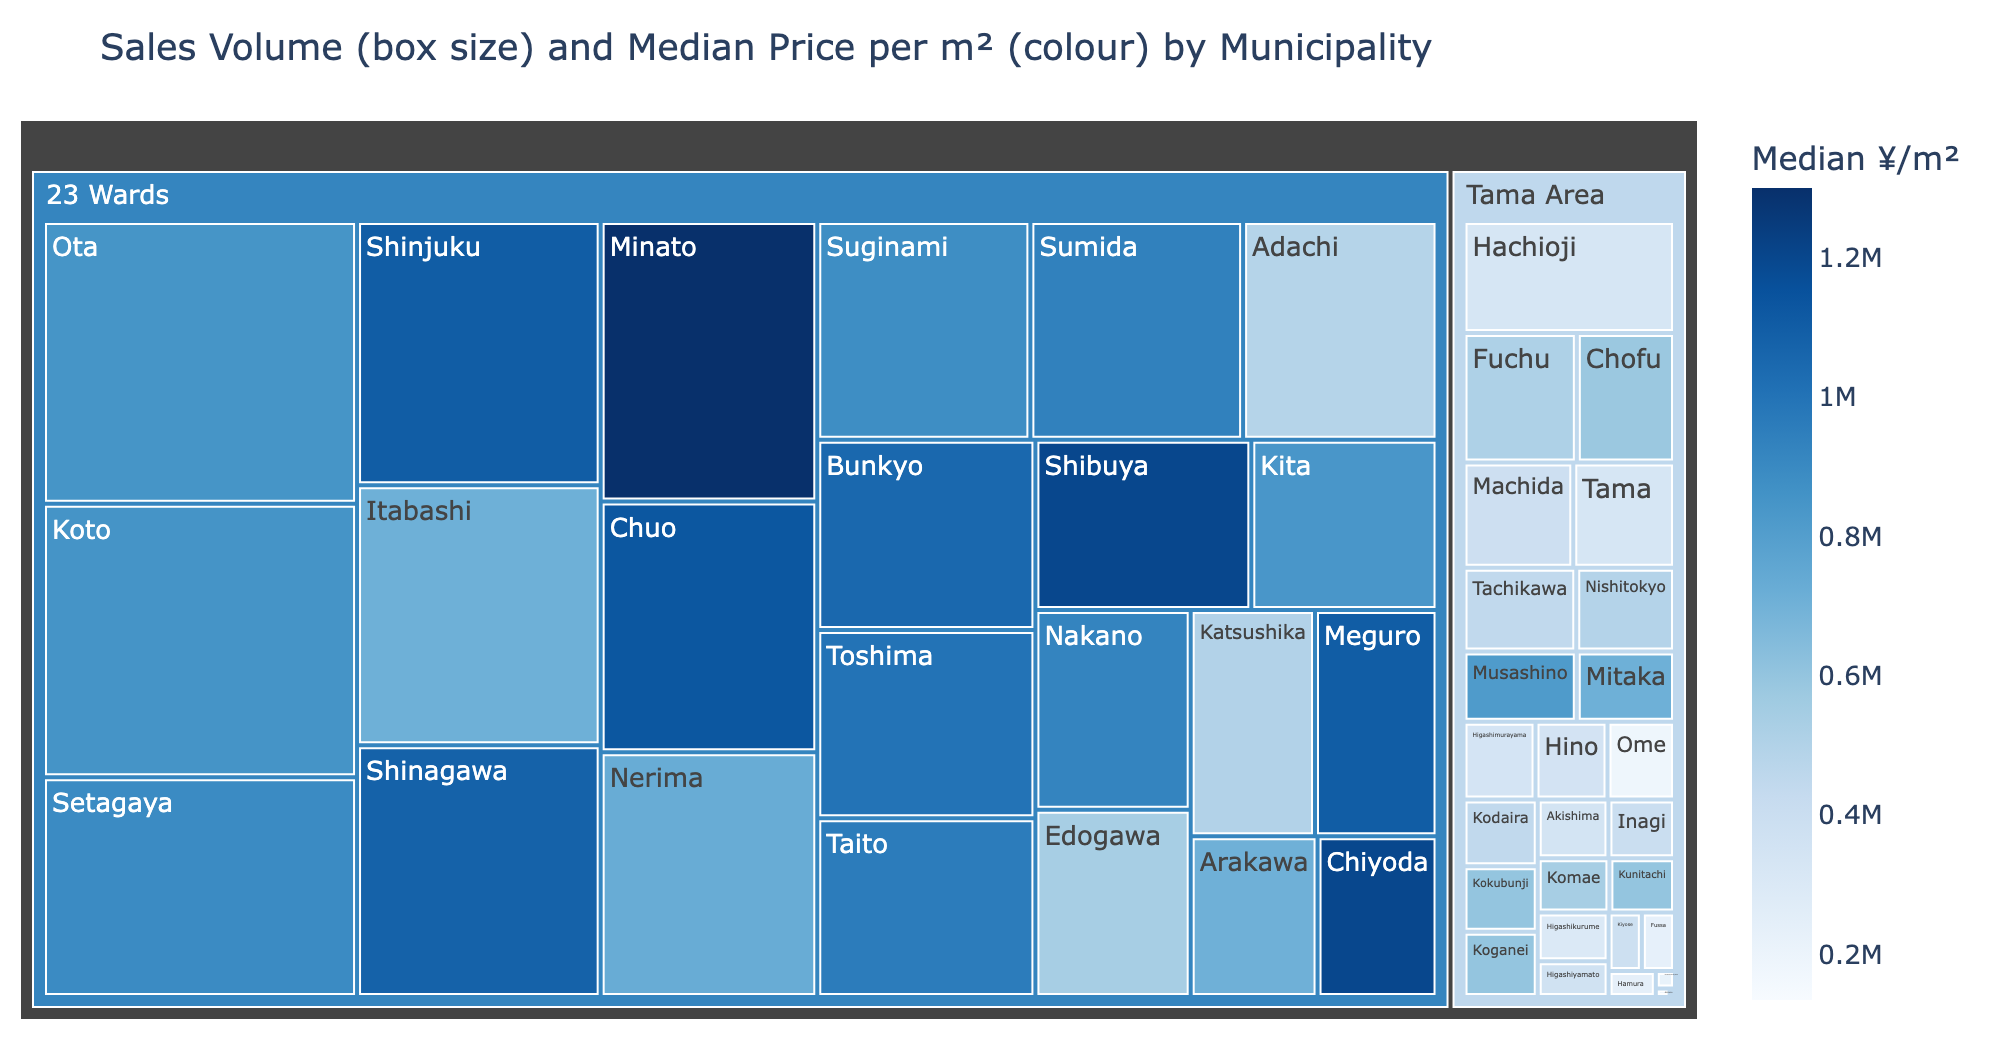

In [26]:
volume_df = clean_df.groupby(["area_group", "municipality"]).agg(
    sales=("price_yen", "size"), median_ppsqm=("price_per_sqm", "median")).reset_index()

fig = px.treemap(volume_df, path=["area_group", "municipality"], values="sales",
                 color="median_ppsqm", color_continuous_scale="Blues",
                 title="Sales Volume (box size) and Median Price per m² (colour) by Municipality",
                 labels={"median_ppsqm": "Median ¥/m²"})
fig.update_layout(margin=dict(t=60, l=10, r=10, b=10), font=dict(size=13))
show_plotly(fig, "09_sales_volume_treemap")

Most condominium transactions take place across Tokyo's 23 wards, making them the largest part of the market. However, areas with the highest number of sales, such as Koto, Ota, Setagaya and Shinjuku, are not necessarily the most expensive in terms of price per square metre. This shows that transaction volume and property prices represent two different aspects of the market.

### 5.8 Correlations between numeric features

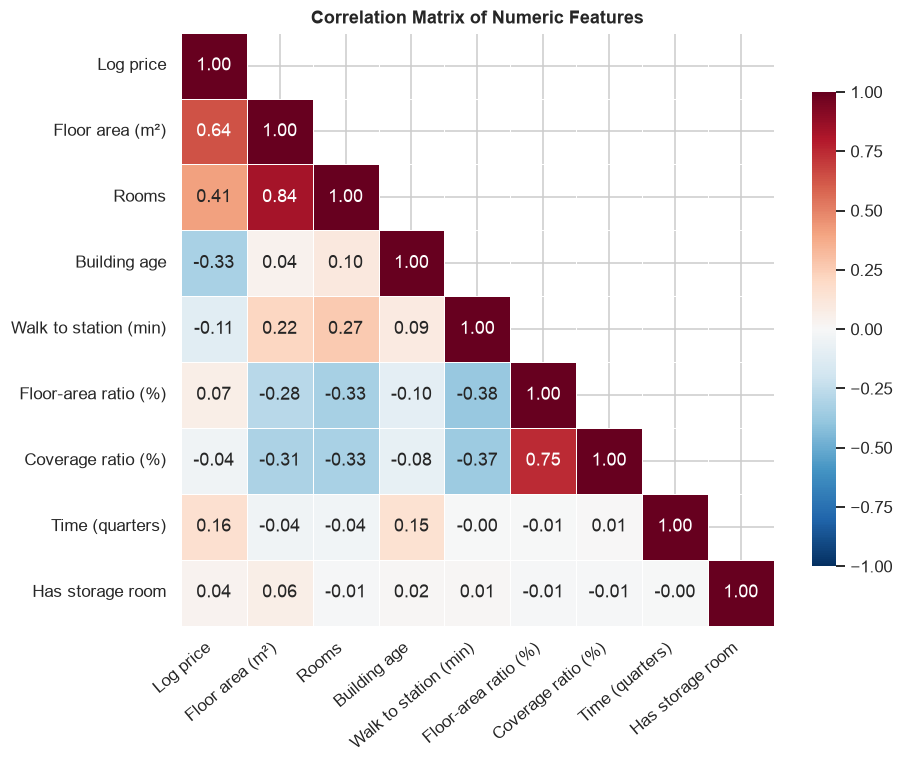

In [27]:
numeric_features = ["log_price", "area_sqm", "rooms", "building_age", "walk_min",
                    "floor_area_ratio_pct", "coverage_ratio_pct", "time_index", "has_storage_room"]
READABLE_NAMES = {
    "log_price": "Log price", "area_sqm": "Floor area (m²)", "rooms": "Rooms",
    "building_age": "Building age", "walk_min": "Walk to station (min)",
    "floor_area_ratio_pct": "Floor-area ratio (%)", "coverage_ratio_pct": "Coverage ratio (%)",
    "time_index": "Time (quarters)", "has_storage_room": "Has storage room",
}
corr_matrix = clean_df[numeric_features].corr().rename(index=READABLE_NAMES, columns=READABLE_NAMES)

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)    # hide the duplicate upper half
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation Matrix of Numeric Features")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
fig.savefig(f"{IMAGE_DIR}/10_correlation_matrix.png", bbox_inches="tight", dpi=130)
plt.show()

\- Floor area and number of rooms: Floor area has the strongest correlation with log price (0.64), followed by the number of rooms (0.41). However, these two features are also highly correlated with each other (0.84), since larger flats generally have more rooms. This creates a problem known as multicollinearity, where individual regression coefficients can become less stable. It also explains why the model gives a negative coefficient to an additional room when the total floor area remains the same (see Notebook 2). Regularisation techniques such as Ridge and Lasso will be explored in Module 24 to address this issue.

\- Building age and transaction time: Building age has a negative correlation with property prices (−0.33), meaning older properties generally sell for less. Transaction time has a positive correlation (+0.16), reflecting the overall increase in property prices over the years.

\- Walking time: Walking time has a relatively weak correlation with price (−0.11), even though the earlier EDA showed that distance from a station has a noticeable impact on prices. This is because station distance matters more when comparing properties within the same area. Properties in outer areas tend to have both longer walking times and different price levels. A simple correlation across the entire dataset cannot fully capture these differences.

\- Zoning ratios: The two zoning-related features are strongly correlated with each other (0.75), but show very little individual correlation with property prices. This suggests that their influence may depend on other factors rather than having a clear direct relationship with price.

## 6. Inferential Statistics

- The EDA revealed several interesting patterns in Tokyo's property market, but I wanted to check whether these differences were statistically meaningful or simply occurred by chance. To do this, I selected four key observations and tested them using a significance level of α = 0.05.

- Since property prices are not normally distributed and tend to be heavily skewed, I mainly used non-parametric statistical tests, including Kruskal–Wallis, Mann–Whitney U and Spearman correlation. These methods are suitable for analysing data without assuming a normal distribution.

- Another point to consider is the size of the dataset. With more than 170,000 transactions, even relatively small differences can appear statistically significant. For this reason, I have also included effect sizes to understand whether the observed differences are meaningful in practical terms, rather than relying on p-values alone.

In [28]:
ALPHA = 0.05

def format_p(p):
    """Readable p-value: very small values shown as '< 0.001'."""
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

### 6.1 Do prices differ between wards?

- H₀: median price per m² is the same in all 23 wards
- H₁: at least one ward differs

In [29]:
ward_df = clean_df[clean_df["area_group"] == "23 Wards"].assign(
    log_ppsqm=lambda d: np.log(d["price_per_sqm"]))
ward_groups = [group["log_ppsqm"].values for _, group in ward_df.groupby("municipality")]

h_stat, p_kw = stats.kruskal(*ward_groups)
n, k = len(ward_df), len(ward_groups)
epsilon_sq = (h_stat - k + 1) / (n - k)          # effect size for Kruskal-Wallis

f_stat, p_anova = stats.f_oneway(*ward_groups)   # parametric version, for comparison

print(f"Kruskal-Wallis: H = {h_stat:,.0f}, p {format_p(p_kw)}, effect size ε² = {epsilon_sq:.2f}")
print(f"One-way ANOVA:  F = {f_stat:,.0f}, p {format_p(p_anova)}")

Kruskal-Wallis: H = 46,278, p < 0.001, effect size ε² = 0.31
One-way ANOVA:  F = 3,528, p < 0.001


### 6.2 Is the renovation premium real once building age is controlled?

H₀: renovation has no effect on price.

In [30]:
renovated = clean_df.loc[clean_df["renovation"] == "Renovated", "price_per_sqm"]
not_renovated = clean_df.loc[clean_df["renovation"] == "Not renovated", "price_per_sqm"]
_, p_naive = stats.mannwhitneyu(renovated, not_renovated)
print(f"(a) Naive comparison: renovated median ¥{renovated.median():,.0f}/m² vs "
      f"not renovated ¥{not_renovated.median():,.0f}/m², p {format_p(p_naive)}")

# (b) Compare like with like: within the same building-age band
rows = []
for band in ["11-20", "21-30", "31-40"]:
    band_df = clean_df[clean_df["age_bucket"] == band]
    ren = band_df.loc[band_df["renovation"] == "Renovated", "price_per_sqm"]
    not_ren = band_df.loc[band_df["renovation"] == "Not renovated", "price_per_sqm"]
    _, p_band = stats.mannwhitneyu(ren, not_ren)
    rows.append({"age_band": band, "renovated_n": len(ren), "not_renovated_n": len(not_ren),
                 "median_difference_pct": round((ren.median() / not_ren.median() - 1) * 100, 1),
                 "p_value": format_p(p_band)})
display(pd.DataFrame(rows).set_index("age_band"))

(a) Naive comparison: renovated median ¥750,000/m² vs not renovated ¥880,000/m², p < 0.001


,renovated_n,not_renovated_n,median_difference_pct,p_value
age_band,,,,
11-20,10517,38803,-4.00,< 0.001
21-30,10479,17366,10.00,< 0.001
31-40,8175,10683,17.10,< 0.001


**Result:** The Kruskal–Wallis test returned H = 46,278 with p < 0.001. This means I can reject the null hypothesis and conclude that price per m² differs significantly across Tokyo's 23 wards. The effect size is also large (ε² = 0.31), suggesting that ward location accounts for approximately 31% of the variation in price rankings. A one-way ANOVA confirmed the same result (F = 3,528, p < 0.001).

**What this means:** Location has a major influence on property prices. The ward a property is in is one of the most important factors to consider, so location needs to be a key feature in the model.

In [31]:
# (c) Regression: control for age, size, station distance, time and location together
ols_model = smf.ols(
    "log_price ~ C(renovation, Treatment('Not renovated')) + building_age + np.log(area_sqm)"
    " + walk_min + time_index + C(municipality)", data=clean_df).fit()

term = [name for name in ols_model.params.index if "Renovated" in name][0]
premium = (np.exp(ols_model.params[term]) - 1) * 100
ci_low, ci_high = (np.exp(ols_model.conf_int().loc[term]) - 1) * 100
print(f"(c) Renovation premium, all else equal: {premium:+.1f}% "
      f"(95% CI {ci_low:+.1f}% to {ci_high:+.1f}%), p {format_p(ols_model.pvalues[term])}, "
      f"model R² = {ols_model.rsquared:.3f}")

(c) Renovation premium, all else equal: +15.8% (95% CI +15.5% to +16.2%), p < 0.001, model R² = 0.873


**Result:**

- **(a) Initial comparison:** Renovated flats have a lower median price per m² than non-renovated flats (¥750K vs ¥880K). At first glance, this suggests that renovation is associated with lower property values.
- **(b) Comparing properties of similar ages:** The results change when properties are grouped by building age. Renovated flats are 4.0% cheaper in the 11–20-year age group, but 10.0% more expensive in the 21–30-year group and 17.1% more expensive in the 31–40-year group. All differences are statistically significant (p < 0.001).
- **(c) Regression analysis:** After controlling for building age, floor area, walking time, sale date and municipality, renovation is associated with a **15.8% higher price** (95% CI: +15.5% to +16.2%, p < 0.001).

**Conclusion:** I reject the null hypothesis. The initial comparison was misleading because of confounding: renovated flats tend to be older, and the negative effect associated with age can outweigh the positive contribution of renovation. Once building age and other factors are taken into account, renovation is associated with a higher property price, with the largest premium observed among older flats.

### 6.3 Layout mix: 23 Wards vs Tama Area

H₀: layout is independent of area.

In [32]:
layout_table = pd.crosstab(clean_df["area_group"], clean_df["layout_group"])
chi2, p_chi, dof, _ = stats.chi2_contingency(layout_table)
cramers_v = np.sqrt(chi2 / (layout_table.values.sum() * (min(layout_table.shape) - 1)))
print(f"Chi-square = {chi2:,.0f}, dof = {dof}, p {format_p(p_chi)}, Cramér's V = {cramers_v:.2f}")

(pd.crosstab(clean_df["area_group"], clean_df["layout_group"], normalize="index") * 100).round(1)

Chi-square = 15,031, dof = 9, p < 0.001, Cramér's V = 0.29


layout_group,1DK,1K,1LDK,1R,2DK,2LDK,3LDK,4LDK,Other,Unknown
area_group,,,,,,,,,,
23 Wards,4.90,33.10,10.40,1.60,3.20,17.70,21.40,1.50,1.10,5.00
Tama Area,1.70,9.00,3.80,0.60,3.50,18.90,48.20,7.10,2.40,4.90


**Result:** The chi-square test returned χ² = 15,031 (9 degrees of freedom, p < 0.001). This indicates that property layout and area are not independent. Cramér's V is 0.29, suggesting a medium-strength relationship between the two variables.

The differences are clear in the results: 1K studio flats account for 33.1% of sales in the 23 wards, compared with just 9.0% in the Tama Area. In contrast, 3LDK family flats make up 48.2% of sales in Tama, compared with 21.4% in the 23 wards.

**What this means:** The two areas have different property-market profiles. The 23 wards have a larger share of studio and smaller investor-oriented properties, while the Tama Area has a stronger focus on family-sized homes. This difference in property mix is worth considering when analysing prices across Tokyo.

### 6.4 Station distance within the 23 wards

In [33]:
rho, p_rho = stats.spearmanr(ward_df["walk_min"], ward_df["log_ppsqm"])
print(f"Spearman correlation (walk time vs price per m², 23 wards): p = {rho:.2f}, p {format_p(p_rho)}")

Spearman correlation (walk time vs price per m², 23 wards): p = -0.24, p < 0.001


**Result:** Within the 23 wards, walking time to the nearest station has a Spearman correlation of ρ = −0.24 with price per m² (p < 0.001). This indicates a weak-to-moderate negative relationship. The correlation is stronger than the −0.11 Pearson correlation observed across all of Tokyo in Section 5.8.

This suggests that, within the same broad area, properties closer to a station tend to have higher prices per m². When the entire city is analysed together, differences between locations partly mask this relationship.

**What this means:** Access to nearby railway stations is an important factor in property pricing. Analysing properties within a more comparable area helps reveal this relationship more clearly.

## 7. Save the Cleaned Dataset

In [34]:
clean_df.to_csv("../data/processed/tokyo_condos_clean.csv.gz", index=False)
print(f"Saved {len(clean_df):,} rows x {clean_df.shape[1]} columns")

Saved 173,745 rows x 38 columns


## 8. Summary


- **Data cleaning:** The dataset was reduced from 182,555 to 173,745 transactions, retaining 95.2% of the original records. This followed the removal of 1,282 non-market sales, 1,507 non-residential units, 1,523 duplicates, 93 records with missing walking-time information and 4,405 outliers.
- **Location:** The median price per m² in Minato is approximately seven times higher than in Ome. Ward location also explains around 31% of the variation in price rankings (Kruskal–Wallis ε² = 0.31).
- **Time:** Between 2015 Q1 and 2025 Q4, median price per m² increased by 59% in the 23 wards and 33% in the Tama Area. This trend highlights the importance of using a time-based train/test split.
- **Station distance and building age:** Flats within a 5-minute walk of a station sell for 2.6 times more per m² than those 21–30 minutes away. Similarly, newly built flats sell for 1.9 times more per m² than properties aged 31–40 years.
- **Renovation:** The initial comparison suggests that renovated flats sell for less. However, after controlling for building age and other factors, renovation is associated with a 15.8% price premium.
- **Market segments:** The 23 wards have a higher share of 1K studio flats, while the Tama Area has a larger share of 3LDK family homes (Cramér's V = 0.29).

The cleaned dataset has been saved and will be used for the modelling work in Notebook 2.